# Introduction to PyTorch

PyTorch is an open-source deep learning framework for Python, developed by Meta AI and now maintained under the Linux Foundation. Its core components are:

- Tensors: Multi-dimensional arrays, similar to NumPy arrays, that can run on a GPU for faster computation.
- Autograd: An automatic differentiation engine that computes gradients, removing the need to derive them by hand.
- torch.nn and torch.optim: Pre-built layers, loss functions, and optimizers for building and training neural networks.

Its dynamic computation graphs make models easy to write and debug, which has made PyTorch one of the most widely used frameworks in research and education.

# Tensors

A tensor is a multi-dimensional array of numbers and the fundamental data structure in PyTorch. It is similar to a NumPy array and is used to store the input data, model parameters (weights and biases), and outputs of a neural network.

## Types of Tensors

| Dimensions | Type | Description | Example |
|:---:|:---|:---|:---|
| 0-D | **Scalar** | A single number | `5.0` |
| 1-D | **Vector** | An ordered list of numbers | `[1, 2, 3]` |
| 2-D | **Matrix** | A grid of numbers with rows and columns | `[[1, 2], [3, 4]]` |
| 3-D and above | **Higher-dimensional** | Stacks of matrices, such as a batch of images with shape `(batch, channels, height, width)` | `(32, 3, 224, 224)` |

## Properties of a Tensor

| Property | Meaning | Example |
|:---|:---|:---|
| **Shape** | The size of each dimension | `torch.Size([2, 3])` |
| **Data type** | The type of values stored | `float32` |
| **Device** | Where the tensor is stored | `cpu` or `cuda` |

Beyond what a NumPy array offers, tensors can run on a GPU for faster computation and can track gradients for automatic differentiation. These two capabilities are what make tensors the foundation of every neural network built in PyTorch.

### 1. Setup

Before working with tensors, we import PyTorch, check the installed version, and detect whether a GPU is available. The `device` variable lets the same code run on either GPU or CPU.

In [4]:
import torch

# Check the installed PyTorch version
print("PyTorch version:", torch.__version__)

# Check whether a GPU (CUDA) is available
print("GPU available:", torch.cuda.is_available())

# Select the device: GPU if available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Set a random seed so the random tensors below are reproducible
torch.manual_seed(42)

PyTorch version: 2.12.0+cpu
GPU available: False
Using device: cpu


### 2. Creating Tensors

Tensors can be created directly from Python data, filled with constant values, generated randomly, or generated as numeric sequences.

In [5]:
# Create tensors from Python data

# Scalar (0-D)
scalar = torch.tensor(5.0)

# Vector (1-D) from a Python list
vector = torch.tensor([1, 2, 3])

# Matrix (2-D) from a nested list
matrix = torch.tensor([[1, 2], [3, 4]])

print("Scalar:", scalar)
print("Vector:", vector)
print("Matrix:\n", matrix)

# constant-value tensors


zeros = torch.zeros(2, 3)        # 2x3 tensor filled with 0
ones = torch.ones(2, 3)          # 2x3 tensor filled with 1
full = torch.full((2, 3), 7)     # 2x3 tensor filled with 7
identity = torch.eye(3)          # 3x3 identity matrix

print("Zeros:\n", zeros)
print("Ones:\n", ones)
print("Full:\n", full)
print("Identity:\n", identity)

#random tensors


rand_uniform = torch.rand(2, 3)    # uniform distribution in [0, 1)
rand_normal = torch.randn(2, 3)    # normal distribution (mean 0, std 1)

print("Uniform random:\n", rand_uniform)
print("Normal random:\n", rand_normal)

# sequences


range_tensor = torch.arange(0, 10, 2)     # values from 0 to 8, step 2
linear_tensor = torch.linspace(0, 1, 5)   # 5 evenly spaced values from 0 to 1

print("arange:", range_tensor)
print("linspace:", linear_tensor)

#tensors shaped like another tensor


x = torch.tensor([[1, 2, 3], [4, 5, 6]])

zeros_like = torch.zeros_like(x)   # zeros with the same shape as x
ones_like = torch.ones_like(x)     # ones with the same shape as x

print("zeros_like:\n", zeros_like)
print("ones_like:\n", ones_like)

Scalar: tensor(5.)
Vector: tensor([1, 2, 3])
Matrix:
 tensor([[1, 2],
        [3, 4]])
Zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
Ones:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
Full:
 tensor([[7, 7, 7],
        [7, 7, 7]])
Identity:
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
Uniform random:
 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])
Normal random:
 tensor([[ 1.1561,  0.3965, -2.4661],
        [ 0.3623,  0.3765, -0.1808]])
arange: tensor([0, 2, 4, 6, 8])
linspace: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
zeros_like:
 tensor([[0, 0, 0],
        [0, 0, 0]])
ones_like:
 tensor([[1, 1, 1],
        [1, 1, 1]])


### 3. Tensor Attributes

Every tensor carries metadata describing its structure and storage. The most important attributes are its shape, number of dimensions, total number of elements, data type, and device.

In [6]:
# basic attributes

t = torch.randn(3, 4)

print("Tensor:\n", t)
print("Shape:", t.shape)               # size of each dimension
print("Dimensions (ndim):", t.ndim)    # number of dimensions
print("Total elements:", t.numel())    # total number of elements (3 x 4 = 12)
print("Data type:", t.dtype)           # default float type is float32
print("Device:", t.device)             # where the tensor is stored

Tensor:
 tensor([[ 0.3930,  0.4327, -1.3627,  1.3564],
        [ 0.6688, -0.7077, -0.3267, -0.2788],
        [-0.4220, -1.3323, -0.3639,  0.1513]])
Shape: torch.Size([3, 4])
Dimensions (ndim): 2
Total elements: 12
Data type: torch.float32
Device: cpu



### Changing the Data Type

Neural networks typically use `float32`. Tensors can be converted between data types when needed, since mixing types in an operation can cause errors.



In [7]:
# changing dtype
a = torch.tensor([1, 2, 3])
print("Original dtype:", a.dtype)       # integers default to int64

b = a.float()                           # convert to float32
print("After .float():", b.dtype)

c = b.long()                            # convert back to int64
print("After .long():", c.dtype)

d = a.to(torch.float64)                 # convert using .to()
print("After .to(torch.float64):", d.dtype)

Original dtype: torch.int64
After .float(): torch.float32
After .long(): torch.int64
After .to(torch.float64): torch.float64


## 4. Indexing and Slicing

- Tensor elements are accessed with the same syntax as Python lists and NumPy arrays.
- **Indexing** retrieves single elements, rows, or columns.
- **Slicing** retrieves ranges using `start:stop:step` (start is inclusive, stop is exclusive).
- **Negative indexing** counts from the end (`-1` is the last element).
- **Boolean masking** selects elements that satisfy a condition.
- **Fancy indexing** selects elements using a list of indices.

In [8]:
# Create a sample tensor

x = torch.tensor([[10, 20, 30, 40],
                  [50, 60, 70, 80],
                  [90, 100, 110, 120]])

print("Tensor:\n", x)


# Single elements, rows and columns

print("Element at row 1, column 2:", x[1, 2])   # single element
print("First row:", x[0])                       # entire row
print("First column:", x[:, 0])                 # entire column


# Slicing with ranges and steps

print("First two rows:\n", x[:2])               # rows 0 and 1
print("Columns 1 to 2:\n", x[:, 1:3])           # start inclusive, end exclusive
print("Sub-matrix:\n", x[0:2, 1:3])             # rows 0-1, columns 1-2
print("Every second column:\n", x[:, ::2])      # step of 2


# Negative indexing

print("Last row:", x[-1])                       # -1 refers to the last index
print("Last column:", x[:, -1])
print("Last element:", x[-1, -1])


# Boolean masking

mask = x > 60                                   # True where the condition holds
print("Mask:\n", mask)
print("Elements greater than 60:", x[mask])     # returns a 1-D tensor of matches
print("Even multiples of 20:", x[x % 20 == 0])


# Fancy indexing (selecting with a list of indices)

print("Rows 0 and 2:\n", x[[0, 2]])             # pick specific rows
print("Columns 1 and 3:\n", x[:, [1, 3]])       # pick specific columns
print("Elements (0,1) and (2,3):", x[[0, 2], [1, 3]])   # pairs of (row, column)


# Modifying values using indexing

y = x.clone()                                   # copy so the original is unchanged
y[0, 0] = 999                                   # change a single element
y[:, 1] = 0                                     # set an entire column to 0
y[y > 100] = -1                                 # replace values using a mask
print("Modified tensor:\n", y)

Tensor:
 tensor([[ 10,  20,  30,  40],
        [ 50,  60,  70,  80],
        [ 90, 100, 110, 120]])
Element at row 1, column 2: tensor(70)
First row: tensor([10, 20, 30, 40])
First column: tensor([10, 50, 90])
First two rows:
 tensor([[10, 20, 30, 40],
        [50, 60, 70, 80]])
Columns 1 to 2:
 tensor([[ 20,  30],
        [ 60,  70],
        [100, 110]])
Sub-matrix:
 tensor([[20, 30],
        [60, 70]])
Every second column:
 tensor([[ 10,  30],
        [ 50,  70],
        [ 90, 110]])
Last row: tensor([ 90, 100, 110, 120])
Last column: tensor([ 40,  80, 120])
Last element: tensor(120)
Mask:
 tensor([[False, False, False, False],
        [False, False,  True,  True],
        [ True,  True,  True,  True]])
Elements greater than 60: tensor([ 70,  80,  90, 100, 110, 120])
Even multiples of 20: tensor([ 20,  40,  60,  80, 100, 120])
Rows 0 and 2:
 tensor([[ 10,  20,  30,  40],
        [ 90, 100, 110, 120]])
Columns 1 and 3:
 tensor([[ 20,  40],
        [ 60,  80],
        [100, 120]])
Elem

## 5. Element-wise Operations & Matrix Operations

### Element-wise Operations

Applied to each position independently. The tensors must have the same shape (or be broadcastable).

| Category | Operations |
|:---|:---|
| **Arithmetic** | `+`, `-`, `*`, `/`, `**`, `//` (floor division), `%` (remainder) |
| **Math functions** | `sqrt`, `exp`, `log`, `abs`, `sin`, `cos`, `tanh`, `sigmoid` |
| **Rounding** | `floor`, `ceil`, `round` |
| **Comparison** | `>`, `<`, `==`, `torch.maximum`, `torch.minimum` |
| **Logical** | `torch.logical_and`, `torch.logical_or`, `torch.logical_not` |
| **Conditional** | `torch.clamp` limits values to a range; `torch.where` chooses between two tensors based on a condition |
| **In-place** | A trailing underscore modifies the tensor itself, e.g. `a.add_(1)`, `a.mul_(2)` |

### Matrix Operations

`*` performs **element-wise** multiplication, while `@` (or `torch.matmul`) performs **matrix multiplication**. For `A @ B`, the number of columns in A must equal the number of rows in B.

| Operation | Function | Notes |
|:---|:---|:---|
| Matrix multiplication | `@`, `torch.matmul`, `torch.mm` | `torch.mm` works on 2-D tensors only |
| Batched multiplication | `torch.bmm` | Multiplies a batch of matrices at once |
| Transpose | `.T` | Swaps rows and columns |
| Dot product | `torch.dot` | 1-D tensors only |
| Outer product | `torch.outer` | Two vectors produce a matrix |
| Trace and diagonal | `torch.trace`, `torch.diag` | Sum of diagonal / extract or build a diagonal |
| Inverse | `torch.linalg.inv` | Square, invertible matrices only |
| Determinant | `torch.linalg.det` | Square matrices only |
| Rank | `torch.linalg.matrix_rank` | Number of independent rows or columns |
| Solve linear system | `torch.linalg.solve` | Solves `Ax = b` |
| Norm | `torch.linalg.norm` | Vector and matrix norms |
| Eigenvalues | `torch.linalg.eigvals`, `eigh` | `eigvals` returns complex numbers; `eigh` is for symmetric matrices |
| Decompositions | `torch.linalg.svd`, `qr` | Singular value and QR decomposition |
| Einstein summation | `torch.einsum` | Index notation for custom tensor contractions |

## 6. Reduction Operations & Reshaping and Manipulating

**Reduction operations**
- Collapse a tensor into a smaller one by aggregating values (`sum`, `mean`, `max`, `min`, `std`).
- `argmax` / `argmin` return the **position** of the largest / smallest value.
- The `dim` argument sets the direction: `dim=0` reduces down the rows (one result per column), and `dim=1` reduces across the columns (one result per row).

**Reshaping and manipulating**
- `view` / `reshape` change the shape without changing the data.
- `squeeze` / `unsqueeze` remove / add dimensions of size 1.
- `flatten` converts a tensor to 1-D.
- `permute` / `transpose` reorder dimensions.
- `torch.cat` joins tensors along an existing dimension, while `torch.stack` joins them along a new one.
- `torch.split` / `torch.chunk` break a tensor into pieces.

In [12]:
# Element-wise arithmetic

a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])

print("a + b:", a + b)
print("a - b:", a - b)
print("a * b:", a * b)                  # element-wise multiplication
print("a / b:", a / b)
print("a ** 2:", a ** 2)                # power
print("b // a (floor division):", b // a)
print("b % a (remainder):", b % a)


# Element-wise math functions

print("sqrt(a):", torch.sqrt(a))
print("exp(a):", torch.exp(a))
print("log(a):", torch.log(a))
print("abs of [-1, 2, -3]:", torch.abs(torch.tensor([-1, 2, -3])))
print("sin(a):", torch.sin(a))
print("cos(a):", torch.cos(a))
print("tanh(a):", torch.tanh(a))
print("sigmoid(a):", torch.sigmoid(a))


# Rounding functions

r = torch.tensor([1.2, 2.5, -1.7, 3.8])
print("floor:", torch.floor(r))
print("ceil:", torch.ceil(r))
print("round:", torch.round(r))         # 2.5 rounds to 2 (round half to even)


# Comparison operators

print("a > 2:", a > 2)
print("a < b:", a < b)
print("a == b:", a == b)
print("Element-wise max:", torch.maximum(a, b))
print("Element-wise min:", torch.minimum(a, b))


# Logical operations

p = torch.tensor([True, True, False, False])
q = torch.tensor([True, False, True, False])

print("logical_and:", torch.logical_and(p, q))
print("logical_or:", torch.logical_or(p, q))
print("logical_not:", torch.logical_not(p))


# Clamp and where

print("clamp(a, min=1.5, max=2.5):", torch.clamp(a, min=1.5, max=2.5))      # limit values to a range
print("where(a > 2, a, 0):", torch.where(a > 2, a, torch.zeros_like(a)))    # keep a where True, else 0


# In-place operations (trailing underscore modifies the tensor itself)

c = torch.tensor([1.0, 2.0, 3.0])
c.add_(10)                              # c is now [11, 12, 13]
print("After add_(10):", c)
c.mul_(2)                               # c is now [22, 24, 26]
print("After mul_(2):", c)


# Matrix multiplication

A = torch.tensor([[1.0, 2.0],
                  [3.0, 4.0]])
B = torch.tensor([[5.0, 6.0],
                  [7.0, 8.0]])

print("A @ B (matrix multiplication):\n", A @ B)
print("torch.matmul(A, B):\n", torch.matmul(A, B))   # same result as @
print("torch.mm(A, B):\n", torch.mm(A, B))           # 2-D only


# Element-wise vs matrix multiplication

print("A * B (element-wise):\n", A * B)
print("A @ B (matrix):\n", A @ B)


# Non-square matrix multiplication: (2x3) @ (3x2) -> (2x2)

C = torch.randn(2, 3)
D = torch.randn(3, 2)
print("Shape of C @ D:", (C @ D).shape)


# Batched matrix multiplication: (4, 2, 3) @ (4, 3, 2) -> (4, 2, 2)

batch1 = torch.randn(4, 2, 3)
batch2 = torch.randn(4, 3, 2)
print("Shape of torch.bmm:", torch.bmm(batch1, batch2).shape)


# Transpose

print("A transpose:\n", A.T)
print("C shape:", C.shape, "-> C.T shape:", C.T.shape)


# Dot product (1-D tensors only)

print("Dot product of a and b:", torch.dot(a, b))   # 1*4 + 2*5 + 3*6 = 32


# Outer product

print("Outer product of a and b:\n", torch.outer(a, b))   # shape (3, 3)


# Trace and diagonal

print("Trace of A:", torch.trace(A))                # 1 + 4 = 5
print("Diagonal of A:", torch.diag(A))              # extracts [1, 4]
print("Diagonal matrix from a:\n", torch.diag(a))   # builds a matrix from a vector


# Inverse and determinant (square matrices only)

print("Determinant of A:", torch.linalg.det(A))     # 1*4 - 2*3 = -2
A_inv = torch.linalg.inv(A)
print("Inverse of A:\n", A_inv)
print("A @ A_inv (approximately identity):\n", A @ A_inv)   # tiny rounding errors are normal


# Matrix rank

print("Rank of A:", torch.linalg.matrix_rank(A))


# Solving a linear system Ax = rhs

rhs = torch.tensor([5.0, 6.0])
x_sol = torch.linalg.solve(A, rhs)
print("Solution x of Ax = rhs:", x_sol)
print("Check A @ x:", A @ x_sol)                    # should equal rhs


# Norm

print("Norm of a:", torch.linalg.norm(a))           # sqrt(1 + 4 + 9)
print("Norm of A (Frobenius):", torch.linalg.norm(A))


# Eigenvalues

print("Eigenvalues of A (complex):", torch.linalg.eigvals(A))

S = torch.tensor([[2.0, 1.0],
                  [1.0, 2.0]])                      # symmetric matrix
eigvals, eigvecs = torch.linalg.eigh(S)             # eigh is for symmetric matrices
print("Eigenvalues of S (eigh):", eigvals)
print("Eigenvectors of S:\n", eigvecs)


# Decompositions

U, S_vals, Vh = torch.linalg.svd(A)
print("SVD singular values:", S_vals)

Q, R = torch.linalg.qr(A)
print("QR decomposition -> Q:\n", Q)
print("QR decomposition -> R:\n", R)
print("Q @ R (reconstructs A):\n", Q @ R)


# Einsum (index notation)

print("einsum matrix multiplication:\n", torch.einsum('ij,jk->ik', A, B))   # same as A @ B
print("einsum dot product:", torch.einsum('i,i->', a, b))                    # same as torch.dot
print("einsum transpose:\n", torch.einsum('ij->ji', A))                      # same as A.T

a + b: tensor([5., 7., 9.])
a - b: tensor([-3., -3., -3.])
a * b: tensor([ 4., 10., 18.])
a / b: tensor([0.2500, 0.4000, 0.5000])
a ** 2: tensor([1., 4., 9.])
b // a (floor division): tensor([4., 2., 2.])
b % a (remainder): tensor([0., 1., 0.])
sqrt(a): tensor([1.0000, 1.4142, 1.7321])
exp(a): tensor([ 2.7183,  7.3891, 20.0855])
log(a): tensor([0.0000, 0.6931, 1.0986])
abs of [-1, 2, -3]: tensor([1, 2, 3])
sin(a): tensor([0.8415, 0.9093, 0.1411])
cos(a): tensor([ 0.5403, -0.4161, -0.9900])
tanh(a): tensor([0.7616, 0.9640, 0.9951])
sigmoid(a): tensor([0.7311, 0.8808, 0.9526])
floor: tensor([ 1.,  2., -2.,  3.])
ceil: tensor([ 2.,  3., -1.,  4.])
round: tensor([ 1.,  2., -2.,  4.])
a > 2: tensor([False, False,  True])
a < b: tensor([True, True, True])
a == b: tensor([False, False, False])
Element-wise max: tensor([4., 5., 6.])
Element-wise min: tensor([1., 2., 3.])
logical_and: tensor([ True, False, False, False])
logical_or: tensor([ True,  True,  True, False])
logical_not: tensor([Fals

In [9]:
# Reduction operations

x = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])

print("Tensor:\n", x)
print("Sum:", x.sum())
print("Mean:", x.mean())
print("Max:", x.max())
print("Min:", x.min())
print("Standard deviation:", x.std())


# Argmax and argmin (position of the max / min value)

print("Argmax (flattened index):", x.argmax())
print("Argmin (flattened index):", x.argmin())
print("Argmax along dim=1 (per row):", x.argmax(dim=1))


# Reductions along a specific dimension

print("Sum along dim=0 (per column):", x.sum(dim=0))
print("Sum along dim=1 (per row):", x.sum(dim=1))
print("Mean along dim=0:", x.mean(dim=0))
print("Max along dim=1:", x.max(dim=1).values)


# Reshaping with view and reshape

r = torch.arange(12)
print("Original:", r, "| shape:", r.shape)
print("view(3, 4):\n", r.view(3, 4))
print("reshape(2, 6):\n", r.reshape(2, 6))
print("reshape(-1, 4):\n", r.reshape(-1, 4))     # -1 means "infer this dimension"


# Squeeze and unsqueeze

s = torch.tensor([1, 2, 3])
print("Original shape:", s.shape)
print("unsqueeze(0) shape:", s.unsqueeze(0).shape)   # (3,) -> (1, 3)
print("unsqueeze(1) shape:", s.unsqueeze(1).shape)   # (3,) -> (3, 1)

u = torch.zeros(1, 3, 1)
print("Before squeeze:", u.shape)
print("After squeeze:", u.squeeze().shape)           # removes all size-1 dimensions


# Flatten

m = torch.tensor([[1, 2], [3, 4], [5, 6]])
print("Flattened:", m.flatten())


# Permute and transpose

img = torch.randn(2, 3, 4)                            # e.g. (batch, rows, columns)
print("Original shape:", img.shape)
print("permute(2, 0, 1) shape:", img.permute(2, 0, 1).shape)
print("transpose(0, 1) shape:", img.transpose(0, 1).shape)


# Concatenating and stacking

p = torch.tensor([[1, 2], [3, 4]])
q = torch.tensor([[5, 6], [7, 8]])

print("cat along dim=0:\n", torch.cat([p, q], dim=0))   # shape (4, 2)
print("cat along dim=1:\n", torch.cat([p, q], dim=1))   # shape (2, 4)
print("stack (new dimension):", torch.stack([p, q]).shape)   # shape (2, 2, 2)


# Splitting

w = torch.arange(10)
print("split into pieces of size 5:", torch.split(w, 5))
print("chunk into 2 pieces:", torch.chunk(w, 2))

Tensor:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
Sum: tensor(21.)
Mean: tensor(3.5000)
Max: tensor(6.)
Min: tensor(1.)
Standard deviation: tensor(1.8708)
Argmax (flattened index): tensor(5)
Argmin (flattened index): tensor(0)
Argmax along dim=1 (per row): tensor([2, 2])
Sum along dim=0 (per column): tensor([5., 7., 9.])
Sum along dim=1 (per row): tensor([ 6., 15.])
Mean along dim=0: tensor([2.5000, 3.5000, 4.5000])
Max along dim=1: tensor([3., 6.])
Original: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]) | shape: torch.Size([12])
view(3, 4):
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
reshape(2, 6):
 tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])
reshape(-1, 4):
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Original shape: torch.Size([3])
unsqueeze(0) shape: torch.Size([1, 3])
unsqueeze(1) shape: torch.Size([3, 1])
Before squeeze: torch.Size([1, 3, 1])
After squeeze: torch.Size([3

## 7. Broadcasting & NumPy Interoperability

**Broadcasting**
- Lets PyTorch operate on tensors of different shapes by automatically "stretching" the smaller one.
- Shapes are compared from the **last dimension backwards**; two dimensions are compatible if they are equal or one of them is 1.
- It is how a bias vector gets added to a whole batch in a neural network.

**NumPy interoperability**
- `torch.from_numpy()` converts a NumPy array to a tensor, and `.numpy()` converts a (CPU) tensor back.
- On the CPU, the two **share the same memory**, so changing one changes the other.
- Use `torch.tensor(array)` or `.clone()` when an independent copy is needed.

In [10]:
# Broadcasting: adding a vector to a matrix

M = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])               # shape (2, 3)
v = torch.tensor([10, 20, 30])              # shape (3,)

print("Matrix + vector:\n", M + v)          # v is stretched across both rows


# Broadcasting: column vector with row vector

col = torch.tensor([[1], [2], [3]])         # shape (3, 1)
row = torch.tensor([[10, 20, 30, 40]])      # shape (1, 4)

print("Column shape:", col.shape, "| Row shape:", row.shape)
print("col + row shape:", (col + row).shape)    # broadcasts to (3, 4)
print("col + row:\n", col + row)


# Broadcasting: scalar with a tensor

print("Matrix * 2:\n", M * 2)


# Incompatible shapes raise an error

try:
    bad = torch.ones(2, 3) + torch.ones(2, 4)
except RuntimeError as e:
    print("Error:", e)


# NumPy to tensor

import numpy as np

np_array = np.array([[1.0, 2.0], [3.0, 4.0]])
t_from_np = torch.from_numpy(np_array)
print("NumPy array:\n", np_array)
print("Tensor from NumPy:\n", t_from_np)


# Tensor to NumPy

t = torch.tensor([1.0, 2.0, 3.0])
np_from_t = t.numpy()
print("NumPy from tensor:", np_from_t, "| type:", type(np_from_t))


# Shared memory demonstration (on CPU)

arr = np.array([1, 2, 3])
tensor_shared = torch.from_numpy(arr)

arr[0] = 100                                 # change the NumPy array
print("Tensor after changing NumPy array:", tensor_shared)   # tensor changes too

tensor_shared[1] = 200                       # change the tensor
print("NumPy array after changing tensor:", arr)             # array changes too


# Making an independent copy

arr2 = np.array([1, 2, 3])
tensor_copy = torch.tensor(arr2)             # copies the data
arr2[0] = 100
print("Copied tensor is unaffected:", tensor_copy)

Matrix + vector:
 tensor([[11, 22, 33],
        [14, 25, 36]])
Column shape: torch.Size([3, 1]) | Row shape: torch.Size([1, 4])
col + row shape: torch.Size([3, 4])
col + row:
 tensor([[11, 21, 31, 41],
        [12, 22, 32, 42],
        [13, 23, 33, 43]])
Matrix * 2:
 tensor([[ 2,  4,  6],
        [ 8, 10, 12]])
Error: The size of tensor a (3) must match the size of tensor b (4) at non-singleton dimension 1
NumPy array:
 [[1. 2.]
 [3. 4.]]
Tensor from NumPy:
 tensor([[1., 2.],
        [3., 4.]], dtype=torch.float64)
NumPy from tensor: [1. 2. 3.] | type: <class 'numpy.ndarray'>
Tensor after changing NumPy array: tensor([100,   2,   3])
NumPy array after changing tensor: [100 200   3]
Copied tensor is unaffected: tensor([1, 2, 3])


## Part B: Linear Regression

- Linear regression models the relationship between an input `x` and output `y` as a straight line: `y = w·x + b`.
- **Weight (w)** and **bias (b)** are the learnable parameters.
- **Forward pass:** compute predictions from the inputs using the model.
- **Loss calculation:** Mean Squared Error (MSE) measures the average squared difference between predictions and true values.
- **Optimization:** Stochastic Gradient Descent (SGD) updates the parameters in the direction that reduces the loss.
- **Training loop:** forward pass, loss, zero gradients, backward pass (`loss.backward()`), and optimizer step, repeated for many epochs.
- **Data:** synthetic data generated from `y = 3x + 2` plus random noise, so the learned parameters can be compared with the true values (w = 3, b = 2).
- **Evaluation:** test MSE, R² score, learned vs true parameters, and a plot of the fitted line.

Train shape: torch.Size([160, 1]) | Test shape: torch.Size([40, 1])
Initial weight: 0.026567697525024414 | Initial bias: 0.1353321075439453
Epoch    0 | Train loss: 335.7596 | Test loss: 50.5737
Epoch  100 | Train loss: 1.0594 | Test loss: 0.6508
Epoch  200 | Train loss: 0.9084 | Test loss: 0.6080
Epoch  300 | Train loss: 0.8553 | Test loss: 0.6114
Epoch  400 | Train loss: 0.8367 | Test loss: 0.6236
Epoch  500 | Train loss: 0.8302 | Test loss: 0.6344
Epoch  600 | Train loss: 0.8279 | Test loss: 0.6421
Epoch  700 | Train loss: 0.8271 | Test loss: 0.6470
Epoch  800 | Train loss: 0.8268 | Test loss: 0.6501
Epoch  900 | Train loss: 0.8267 | Test loss: 0.6520


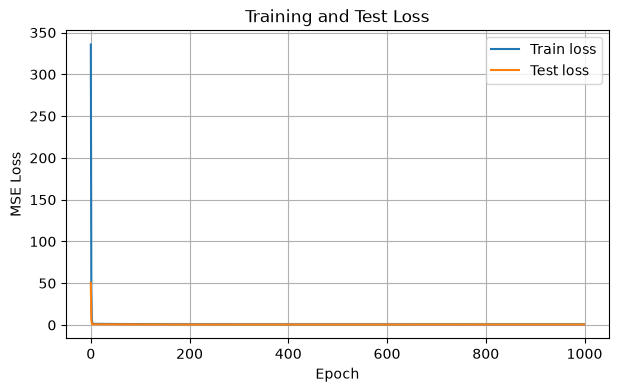


Learned weight: 2.9906 (true: 3)
Learned bias:   2.1993 (true: 2)
Test MSE: 0.6531
Test R² score: 0.9907


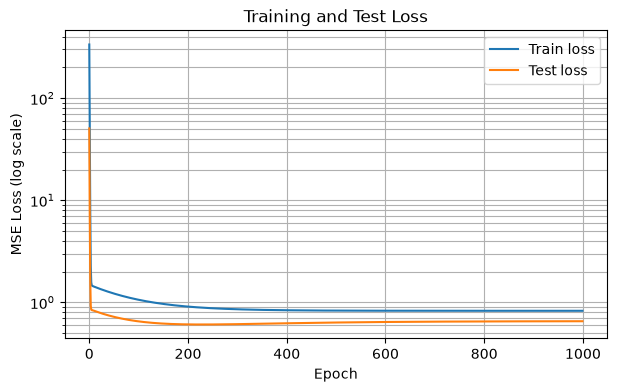

In [15]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)


# Generate synthetic data: y = 3x + 2 + noise

X = torch.rand(200, 1) * 10                    # 200 samples, shape (200, 1)
y = 3 * X + 2 + torch.randn(200, 1)            # true w = 3, true b = 2, plus noise


# Train/test split (80% / 20%)

indices = torch.randperm(200)
train_idx, test_idx = indices[:160], indices[160:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)


# Define the model

class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)          # one input feature, one output

    def forward(self, x):                      # forward pass
        return self.linear(x)

model = LinearRegression()
print("Initial weight:", model.linear.weight.item(), "| Initial bias:", model.linear.bias.item())


# Loss function and optimizer

criterion = nn.MSELoss()                                   # Mean Squared Error
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)   # Stochastic Gradient Descent


# Training loop

epochs = 1000
train_losses = []
test_losses = []

for epoch in range(epochs):
    model.train()
    y_pred = model(X_train)                    # 1. forward pass
    loss = criterion(y_pred, y_train)          # 2. compute loss
    optimizer.zero_grad()                      # 3. clear old gradients
    loss.backward()                            # 4. backward pass (compute gradients)
    optimizer.step()                           # 5. update parameters

    # Track test loss without computing gradients
    model.eval()
    with torch.no_grad():
        test_loss = criterion(model(X_test), y_test)

    train_losses.append(loss.item())
    test_losses.append(test_loss.item())

    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Train loss: {loss.item():.4f} | Test loss: {test_loss.item():.4f}")


# Plot the loss curves

plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Train loss")
plt.plot(test_losses, label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid(True)
plt.show()


# Model evaluation

learned_w = model.linear.weight.item()
learned_b = model.linear.bias.item()
print(f"\nLearned weight: {learned_w:.4f} (true: 3)")
print(f"Learned bias:   {learned_b:.4f} (true: 2)")

model.eval()
with torch.no_grad():
    y_test_pred = model(X_test)
    test_mse = criterion(y_test_pred, y_test).item()
    ss_res = ((y_test - y_test_pred) ** 2).sum()
    ss_tot = ((y_test - y_test.mean()) ** 2).sum()
    r2 = (1 - ss_res / ss_tot).item()

print(f"Test MSE: {test_mse:.4f}")
print(f"Test R² score: {r2:.4f}")


# Plot the fitted line over the data

with torch.no_grad():
    x_line = torch.linspace(0, 10, 100).unsqueeze(1)
    y_line = model(x_line)

plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Train loss")
plt.plot(test_losses, label="Test loss")
plt.yscale("log")                      # log scale makes both the big drop and the small details visible
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (log scale)")
plt.title("Training and Test Loss")
plt.legend()
plt.grid(True, which="both")
plt.show()